In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("StudentsAnnualScoreInHistoryGeographySubject.csv")

In [3]:
df.head()

,Gender,Test_01,Exam_01,Test_02,Exam_02,Test_03,Exam_03,Annual_Score,Success,Unnamed: 9
0,F,72.50,93.75,81.25,86.25,100.0,86.25,87.36,1,NaN
1,F,68.75,81.25,65.00,56.25,90.0,71.25,71.25,1,NaN
2,F,67.50,58.75,42.50,45.00,85.0,50.00,55.83,1,NaN
3,F,58.75,87.50,75.00,76.25,100.0,81.25,80.42,1,NaN
4,F,90.00,83.75,70.00,93.75,90.0,88.75,86.94,1,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 634 entries, 0 to 633
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Gender        634 non-null    str    
 1   Test_01       634 non-null    float64
 2   Exam_01       634 non-null    float64
 3   Test_02       634 non-null    float64
 4   Exam_02       634 non-null    float64
 5   Test_03       634 non-null    float64
 6   Exam_03       634 non-null    float64
 7   Annual_Score  634 non-null    float64
 8   Success       634 non-null    int64  
 9   Unnamed: 9    0 non-null      float64
dtypes: float64(8), int64(1), str(1)
memory usage: 49.7 KB


In [5]:
df = df.drop("Unnamed: 9",axis=1)

In [6]:
df.head()

,Gender,Test_01,Exam_01,Test_02,Exam_02,Test_03,Exam_03,Annual_Score,Success
0,F,72.50,93.75,81.25,86.25,100.0,86.25,87.36,1
1,F,68.75,81.25,65.00,56.25,90.0,71.25,71.25,1
2,F,67.50,58.75,42.50,45.00,85.0,50.00,55.83,1
3,F,58.75,87.50,75.00,76.25,100.0,81.25,80.42,1
4,F,90.00,83.75,70.00,93.75,90.0,88.75,86.94,1


In [7]:
gender_map = {
    "F": 0,
    "M": 1
}

In [8]:
df["Gender"].value_counts()

Gender
F    438
M    196
Name: count, dtype: int64

In [9]:
df["Gender"] = df["Gender"].map(gender_map)

In [10]:
df["Gender"]

0      0
1      0
2      0
3      0
4      0
      ..
629    0
630    0
631    0
632    1
633    0
Name: Gender, Length: 634, dtype: int64

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gender,634.0,0.309148,0.462507,0.00,0.000,0.000,1.0000,1.00
Test_01,634.0,61.606940,23.275282,0.00,45.000,62.500,80.0000,100.00
Exam_01,634.0,40.912713,20.049997,0.00,26.880,40.000,48.5925,100.00
Test_02,634.0,54.538644,27.024086,0.00,35.000,56.250,75.0000,101.25
Exam_02,634.0,31.189858,21.371619,0.00,15.000,27.500,42.5000,98.75
Test_03,634.0,66.607177,34.124975,0.00,40.000,78.125,100.0000,100.00
Exam_03,634.0,34.431183,23.640577,0.00,16.250,31.880,45.6200,98.75
Annual_Score,634.0,43.980110,18.250195,2.92,30.925,42.920,56.3550,95.28
Success,634.0,0.365931,0.482070,0.00,0.000,0.000,1.0000,1.00


In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X = df.drop("Success",axis=1)
y = df["Success"]

In [14]:
X_temp,X_test,y_temp,y_test = train_test_split(X,y,test_size=0.2,random_state=15,stratify=y)

In [15]:
X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=0.25,random_state=15,stratify=y)

In [16]:
X_train

,Gender,Test_01,Exam_01,Test_02,Exam_02,Test_03,Exam_03,Annual_Score
282,0,8.75,5.00,47.50,21.88,32.50,18.12,19.86
208,1,25.00,32.50,0.00,17.50,30.00,30.00,23.89
114,0,60.00,72.50,46.25,53.75,43.75,43.75,54.44
275,1,70.00,18.75,27.50,10.62,36.25,9.38,23.47
450,0,20.00,2.50,2.50,8.75,5.00,8.75,7.50
...,...,...,...,...,...,...,...,...
371,0,66.25,46.25,0.00,30.00,100.00,2.50,35.97
15,0,83.75,73.75,30.00,55.00,100.00,76.25,69.31
390,1,75.00,41.88,75.00,29.38,42.50,21.25,41.94
308,0,75.00,29.38,60.00,39.38,92.50,25.00,46.11


In [17]:
import tensorflow as tf

In [18]:
from tensorflow.keras.layers import Dense,Dropout,Input

In [19]:
from tensorflow.keras.models import Sequential

In [20]:
from sklearn.preprocessing import StandardScaler

In [21]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [22]:
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(32,activation="sigmoid"))
model.add(Dropout(0.4))
model.add(Dense(16,activation="sigmoid"))
model.add(Dropout(0.3))
model.add(Dense(1,activation="sigmoid"))

In [23]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [26]:
history = model.fit(X_train,y_train,epochs=50,batch_size=32,validation_data=(X_val,y_val))

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.9558 - loss: 0.1711 - val_accuracy: 0.3648 - val_loss: 2.2462
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9389 - loss: 0.1815 - val_accuracy: 0.3648 - val_loss: 2.2636
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9516 - loss: 0.1735 - val_accuracy: 0.3648 - val_loss: 2.2800
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9747 - loss: 0.1423 - val_accuracy: 0.3648 - val_loss: 2.3045
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9684 - loss: 0.1433 - val_accuracy: 0.3648 - val_loss: 2.3296
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9516 - loss: 0.1574 - val_accuracy: 0.3648 - val_loss: 2.3691
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9558 - loss: 0.1575 - val_accuracy: 0.3648 - val_loss: 2.3944
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9663 - loss: 0.1467 - val_accuracy: 0.3648 - v

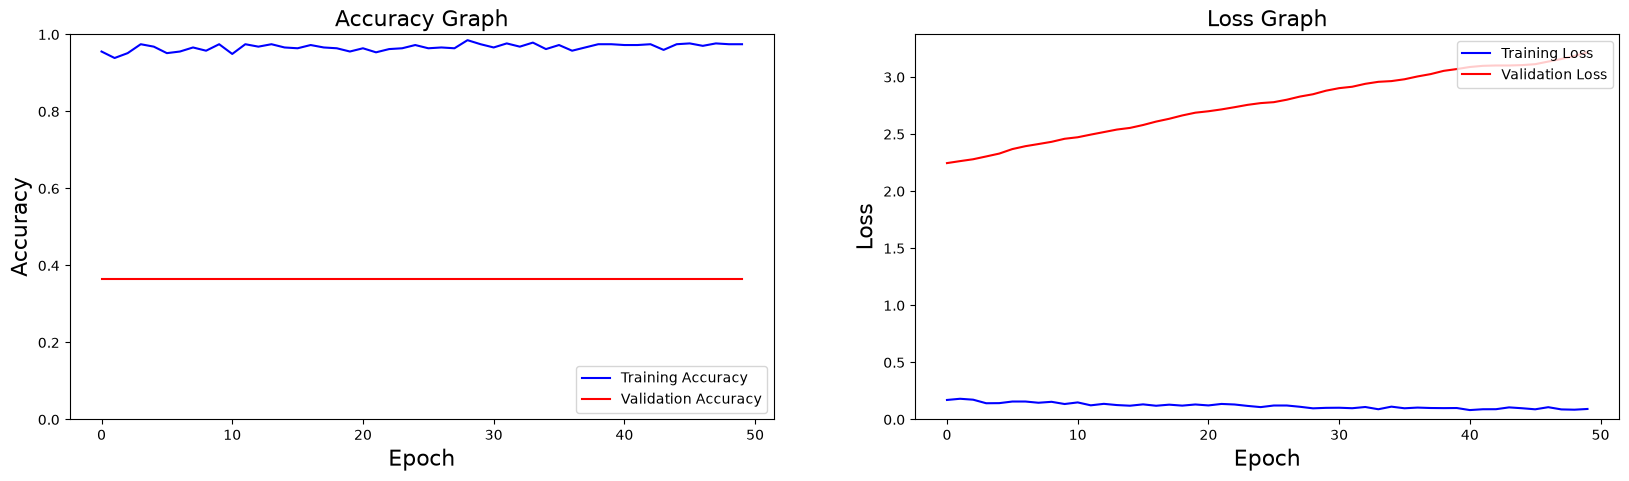

In [27]:
# ------------------------ Graphic 1 ACCURACY ----------------------------

plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='b', label="Training Accuracy")
plt.plot(history.history['val_accuracy'], color='r', label="Validation Accuracy") # Added validation line
plt.legend(loc="lower right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Accuracy', fontsize=16)
plt.ylim([0, 1]) # Standardized to start at 0 for clean visibility
plt.title("Accuracy Graph", fontsize=16)

# ------------------------ Graphic 2 LOSS --------------------------------

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='b', label='Training Loss')
plt.plot(history.history['val_loss'], color='r', label='Validation Loss')
plt.legend(loc="upper right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0, max(plt.ylim())])
plt.title("Loss Graph", fontsize=16)

plt.show()

In [31]:
loss, acc = model.evaluate(X_test,y_test, verbose=False)
print("Test Accuracy: %.1f%%" % (100.0 * acc))
print("Test Loss: %.1f%%" % (100.0 * loss))

Test Accuracy: 97.6%
Test Loss: 5.5%
